## Working datasets

In [1]:
from datasets import load_dataset

dataset = load_dataset("dair-ai/emotion")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

...

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

AttributeError: 'Value' object has no attribute 'names'

In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [3]:
df = dataset["train"].to_pandas()
label_names = dataset["train"].features["label"].names
# label_names
df['label_text'] = df['label'].apply(lambda x: label_names[x])
df


,text,label,label_text
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger
...,...,...,...
15995,i just had a very brief time in the beanbag an...,0,sadness
15996,i am now turning and i feel pathetic that i am...,0,sadness
15997,i feel strong and good overall,1,joy
15998,i feel like this was such a rude comment and i...,3,anger


## Analysis of data using Matplotlib

In [4]:
import matplotlib.pyplot as plt

label_counts = df['label_text'].value_counts(ascending=True)
label_counts

,count
label_text,
surprise,572
love,1304
fear,1937
anger,2159
sadness,4666
joy,5362


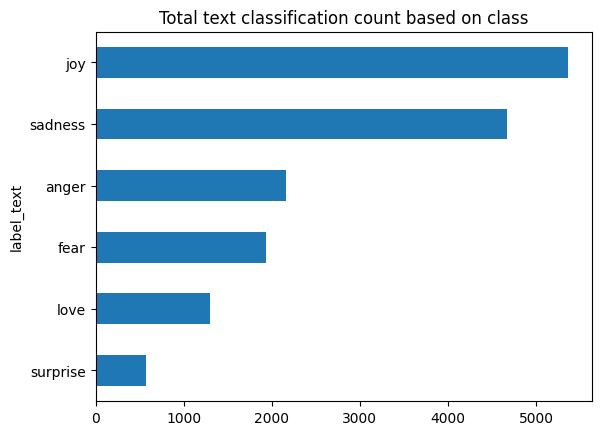

In [5]:
label_counts.plot.barh()
plt.title('Total text classification count based on class')
plt.show()

## Tokenization of data from the raw String

In [6]:
from transformers import AutoTokenizer

model_checkpoint = 'bert-base-uncased'

In [7]:
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

text = "I love ML and ML is the future"
encoded_txt = tokenizer(text)

print(f"Original text: {text}")
print(f"Encoded text: {encoded_txt}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Original text: I love ML and ML is the future
Encoded text: {'input_ids': [101, 1045, 2293, 19875, 1998, 19875, 2003, 1996, 2925, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


## Split the data as 

1) Training data
2) Test Data
3) Validation Data

In [8]:
from sklearn.model_selection import train_test_split
#70% of data = Train data, 20% of data = Test Data, 10% of data = Validation data

train, test = train_test_split(df,test_size = 0.3,stratify = df['label_text'])
test,validation = train_test_split(test,test_size = 1/3,stratify = test['label'])
train.shape, test.shape, validation.shape

((11200, 3), (3200, 3), (1600, 3))

In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [10]:
from datasets import Dataset, DatasetDict

dataset = DatasetDict({
    'train': Dataset.from_pandas(train, preserve_index=False),
    'test': Dataset.from_pandas(test, preserve_index=False),
    'validation': Dataset.from_pandas(validation, preserve_index=False)
})

dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 11200
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 3200
    })
    validation: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 1600
    })
})

In [ ]:
dataset["train"][0],dataset["test"][0],dataset["validation"][0]

({'text': 'ill transfer those that i feel will be useful to next years class to the class website or specific content unit blogs or sites',
  'label': 1,
  'label_text': 'joy'},
 {'text': 'i am way behind with my work on the fantasy novel and i feel very frustrated',
  'label': 3,
  'label_text': 'anger'},
 {'text': 'i feel irritated a lot', 'label': 3, 'label_text': 'anger'})

## Tokenize All the text in the Dataset using Map function of HuggingFace

In [12]:
def tokenize(batch):
    return tokenizer(batch['text'], padding=True, truncation=True)

tokenize(dataset['train'][:3])
# tokenized_datasets = dataset.map(tokenize, batched=True, batch_size=None)

{'input_ids': [[101, 5665, 4651, 2216, 2008, 1045, 2514, 2097, 2022, 6179, 2000, 2279, 2086, 2465, 2000, 1996, 2465, 4037, 2030, 3563, 4180, 3131, 23012, 2030, 4573, 102], [101, 1045, 2514, 2009, 2052, 2025, 2022, 8295, 1997, 2033, 2025, 11582, 2017, 2055, 1996, 17945, 2591, 25332, 5307, 8124, 102, 0, 0, 0, 0, 0], [101, 1045, 3432, 2056, 2129, 3374, 1045, 2572, 1998, 2074, 2288, 2041, 2013, 2014, 2482, 1998, 2288, 2046, 2026, 2160, 3110, 15035, 102, 0, 0, 0]], 'token_type_ids': [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0]]}

In [13]:
encoded = dataset.map(tokenize, batched=True, batch_size=None)

Map:   0%|          | 0/11200 [00:00<?, ? examples/s]

Map:   0%|          | 0/3200 [00:00<?, ? examples/s]

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

In [14]:
encoded

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 11200
    })
    test: Dataset({
        features: ['text', 'label', 'label_text', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3200
    })
    validation: Dataset({
        features: ['text', 'label', 'label_text', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1600
    })
})

## Working with Models

In [15]:
from transformers import AutoModel
model = AutoModel.from_pretrained(model_checkpoint)
# model.config.id2label
model.config.id2label, model.config.label2id

label2id = {label: i for i, label in enumerate(label_names)}
id2label = {i: label for i, label in enumerate(label_names)}

label2id, id2label

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


({'sadness': 0, 'joy': 1, 'love': 2, 'anger': 3, 'fear': 4, 'surprise': 5},
 {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'})

In [ ]:
model

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
  

In [17]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer, AutoConfig
import torch


if torch.has_mps:
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
    
config = AutoConfig.from_pretrained(model_checkpoint, label2id=label2id, id2label=id2label)
model = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, config=config).to(device)

/tmp/ipykernel_1033/3954972081.py:5: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  if torch.has_mps:


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
model.config

BertConfig {
  "add_cross_attention": false,
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "classifier_dropout": null,
  "dtype": "float32",
  "eos_token_id": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "id2label": {
    "0": "sadness",
    "1": "joy",
    "2": "love",
    "3": "anger",
    "4": "fear",
    "5": "surprise"
  },
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "label2id": {
    "anger": 3,
    "fear": 4,
    "joy": 1,
    "love": 2,
    "sadness": 0,
    "surprise": 5
  },
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "tie_word_embeddings": true,
  "transformers_version": "5.13.1",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size":

## Model Training

1. Training Argument 
2. Build the trainer along with the argument
3. Start the training itself.

Evalute the model = Compute metrics

In [19]:
%pip install --upgrade "accelerate>=1.1.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 14.9 MB/s eta 0:00:00
  Attempting uninstall: accelerate
    Found existing installation: accelerate 1.14.0
    Uninstalling accelerate-1.14.0:
      Successfully uninstalled accelerate-1.14.0


In [20]:
from transformers import TrainingArguments

batch_size = 64
training_dir = "bert_base_uncased_trained_model"

training_args = TrainingArguments(
                                  output_dir=training_dir,
                                  # overwrite_output_dir=True,
                                  num_train_epochs= 2,
                                  learning_rate= 2e-5,
                                  per_device_eval_batch_size=batch_size,
                                  per_device_train_batch_size=batch_size,
                                  weight_decay=0.01,
                                  eval_strategy='epoch',
                                  disable_tqdm=False)

### Build the Compute Metrics

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)

    f1 = f1_score(labels,preds , average = 'weighted')    
    acc = accuracy_score(labels, preds)
    return {'accuracy': acc, 'F1 score': f1}

### Building a Trainer

In [22]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    compute_metrics=compute_metrics,
    train_dataset= encoded['train'],
    eval_dataset=encoded['validation'],
    processing_class=tokenizer,
)

trainer

In [23]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
# print("Trainer device:", trainer.args.device)
# print("Model device:", next(trainer.model.parameters()).device)
# print("Batch size:", trainer.args.per_device_train_batch_size)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [24]:
trainer.train()


Epoch,Training Loss,Validation Loss,Accuracy,F1 score
1,No log,0.472548,0.855000,0.843896
2,No log,0.291983,0.908750,0.908529


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=350, training_loss=0.6974595860072544, metrics={'train_runtime': 305.7261, 'train_samples_per_second': 73.268, 'train_steps_per_second': 1.145, 'total_flos': 863364156480000.0, 'train_loss': 0.6974595860072544, 'epoch': 2.0})

In [25]:
trainer.save_model("bert_base_uncased_text-classification-model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [26]:
from transformers import pipeline

classifier = pipeline('text-classification', model='bert_base_uncased_text-classification-model')

classifier([
    'I like ML', 
    'I started annoyed with laptops', 
    'I am low today', 
    'I am tensed if I am not going to get the job in ML',
    'I am worried with the current job market'
])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[{'label': 'love', 'score': 0.5060308575630188},
 {'label': 'anger', 'score': 0.9561046361923218},
 {'label': 'sadness', 'score': 0.9614695310592651},
 {'label': 'fear', 'score': 0.8394438624382019},
 {'label': 'fear', 'score': 0.9146478772163391}]

In [ ]:
from transformers import pipeline

classifier = pipeline('text-classification', model='ExecuteAutomation/bert-base-text-classification-model')

classifier([
    'I like ML', 
    'I started annoyed with laptops', 
    'I am low today', 
    'I am tensed if I am not going to get the job in ML',
    'I am worried with the current job market'
])

config.json:   0%|          | 0.00/973 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.22k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

[{'label': 'joy', 'score': 0.9189167618751526},
 {'label': 'anger', 'score': 0.9749674201011658},
 {'label': 'sadness', 'score': 0.9617274403572083},
 {'label': 'fear', 'score': 0.9441773891448975},
 {'label': 'fear', 'score': 0.9487776160240173}]